In [ ]:
%%bash
set -euo pipefail

WORKDIR="/kaggle/working/1kg"
mkdir -p "$WORKDIR"
cd "$WORKDIR"

# 0) plink2
if [ ! -x ./plink2 ]; then
  PLINK_INDEX="https://s3.amazonaws.com/plink2-assets/"
  PLINK_ZIP=$(curl -s "$PLINK_INDEX" | grep -oE 'plink2_linux_x86_64_[0-9]{8}\.zip' | sort | tail -n1)
  curl -fsSL -o "$PLINK_ZIP" "https://s3.amazonaws.com/plink2-assets/${PLINK_ZIP}"
  unzip -o "$PLINK_ZIP" >/dev/null
  chmod +x plink2
fi

# 1) Download 1KG panel and chr20–22 VCF, convert to pgen (with variant ID standardization)
BASE="https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20130502"
test -s panel.tsv || curl -fsSL -o panel.tsv "${BASE}/integrated_call_samples_v3.20130502.ALL.panel"

for C in 20 21 22; do
  VCF="ALL.chr${C}.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz"
  test -s "${VCF}" || curl -fSL -O "${BASE}/${VCF}"
  if [ ! -s "kgp_chr${C}_id.pgen" ]; then
    ./plink2 --vcf "${VCF}" --double-id --snps-only just-acgt --max-alleles 2 \
      --make-pgen --out "kgp_chr${C}"
    ./plink2 --pfile "kgp_chr${C}" \
      --set-all-var-ids @:#:\$r:\$a --new-id-max-allele-len 31 truncate \
      --rm-dup exclude-all \
      --make-pgen --out "kgp_chr${C}_id"
  fi
done

# 2) Merge 20–22 to bed
if [ ! -s kgp_20_22.bed ]; then
  printf "kgp_chr21_id\nkgp_chr22_id\n" > pmerge_list.txt
  ./plink2 --pfile kgp_chr20_id --pmerge-list pmerge_list.txt --make-pgen --out kgp_20_22_pgen
  ./plink2 --pfile kgp_20_22_pgen --make-bed --out kgp_20_22
fi

# 3) Build IID↔(POP,SUPERPOP) mapping (use space-separated table first to avoid awk delimiter confusion)
awk 'NR>1{print $1" "$2" "$3}' panel.tsv > iid_pop_map.txt   # sample pop super
awk 'NR==FNR{pop[$1]=$2; sup[$1]=$3; next} {iid=$2; if(iid in pop) print $1"\t"$2"\t"pop[iid]"\t"sup[iid]}' \
  iid_pop_map.txt kgp_20_22.fam > iid_pop.tsv

echo "iid_pop.tsv lines: $(wc -l < iid_pop.tsv)"
head -n 3 iid_pop.tsv | cat

# 4) Sample 957 (first sample by sub-population, fallback to random 957 if insufficient), use temp files to avoid overwriting
:> keep_957.stage
for P in YRI LWK ESN GWD MSL CEU GBR FIN IBS TSI CHB CHS JPT PJL GIH BEB STU ITU PEL PUR CLM MXL; do
  awk -F'\t' -v P="$P" '$3==P{print $1"\t"$2}' iid_pop.tsv | shuf -n 50 >> keep_957.stage || true
done
awk '!seen[$0]++' keep_957.stage > keep_957.uniq || true
awk 'NR<=957' keep_957.uniq > keep_957.final.txt || true

# If still empty, randomly sample 957 from all samples
if [ ! -s keep_957.final.txt ] || [ "$(wc -l < keep_957.final.txt)" -eq 0 ]; then
  awk '{print $1"\t"$2}' kgp_20_22.fam | shuf -n 957 > keep_957.final.txt
fi
echo "Keep:" $(wc -l < keep_957.final.txt)

# 5) QC + standardize variant IDs
./plink2 --bfile kgp_20_22 --keep keep_957.final.txt \
  --maf 0.05 --geno 0.05 --hwe 1e-6 midp \
  --make-bed --out kgp_qc

./plink2 --bfile kgp_qc \
  --set-all-var-ids @:#:\$r:\$a --new-id-max-allele-len 31 truncate \
  --rm-dup exclude-all \
  --make-bed --out kgp_qc_unique

# 6) Exclude long-range high LD regions (hg19)
cat > highLD_hg19.txt <<'EOF'
6  25000000 35000000  MHC
8  8000000  12000000  chr8_inv
17 40000000 43000000  chr17_highLD
EOF
./plink2 --bfile kgp_qc_unique --exclude range highLD_hg19.txt --make-bed --out kgp_uldl

# 7) LD pruning to exactly 14,389
TARGET=14389
./plink2 --bfile kgp_uldl --indep-pairwise 50 5 0.2 --out pruned_idx || true
awk -v N=${TARGET} '!seen[$0]++{print; if(++c==N) exit}' pruned_idx.prune.in > pruned_exact.in || true
CT=$(wc -l < pruned_exact.in || echo 0)
if [ "$CT" -lt "$TARGET" ]; then
  awk '{print $2}' kgp_uldl.bim > all_snps.txt
  awk 'NR==FNR{ok[$1]=1;next}!ok[$0]' pruned_exact.in all_snps.txt \
    | awk -v K=$((TARGET-CT)) '{print; if(++c==K) exit}' >> pruned_exact.in
fi

./plink2 --bfile kgp_uldl --extract pruned_exact.in --make-bed --out 1kg_957x14389
./plink2 --bfile 1kg_957x14389 --export A --out 1kg_957x14389

# 8) Generate labels for Python use (FID IID POP)
awk -F'\t' 'NR==FNR{key=$1"\t"$2; pop[key]=$3; next} {key=$1"\t"$2; if(key in pop) print $1"\t"$2"\t"pop[key]}' \
  iid_pop.tsv keep_957.final.txt > labels_pop.tsv

ls -lh 1kg_957x14389.raw labels_pop.tsv
echo "All done in $WORKDIR"

PLINK v2.0.0-a.7LM 64-bit Intel (15 Sep 2025)      cog-genomics.org/plink/2.0/
(C) 2005-2025 Shaun Purcell, Christopher Chang   GNU General Public License v3
Logging to kgp_chr20.log.
Options in effect:
  --double-id
  --make-pgen
  --max-alleles 2
  --out kgp_chr20
  --snps-only just-acgt
  --vcf ALL.chr20.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz

Start time: Wed Sep 17 08:02:06 2025
32102 MiB RAM detected, ~31047 available; reserving 16051 MiB for main
workspace.
Using up to 4 compute threads.
--vcf: 1812841 variants scanned.
--vcf: kgp_chr20-temporary.pgen + kgp_chr20-temporary.pvar.zst +
kgp_chr20-temporary.psam written.
2504 samples (0 females, 0 males, 2504 ambiguous; 2504 founders) loaded from
kgp_chr20-temporary.psam.
1739315 out of 1812841 variants loaded from kgp_chr20-temporary.pvar.zst.
Note: No phenotype data present.
1739315 variants remaining after main filters.
Writing kgp_chr20.psam ... done.
Writing kgp_chr20.pvar ... 0%1%2%3%4%5%6%

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  311M  100  311M    0     0  14.1M      0  0:00:22  0:00:22 --:--:-- 15.2M
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  200M  100  200M    0     0  6871k      0  0:00:29  0:00:29 --:--:-- 6899k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  196M  100  196M    0     0  11.5M      0  0:00:16  0:00:16 --:--:-- 8469k


Saved figure to: /kaggle/working/hapmap_like_1kg/spca_scores_compare.png
Times (sec): {'PCA': 4.133, 'SPCA(Alg4.1)': 16.643, 'RND-SPCA': 0.148}


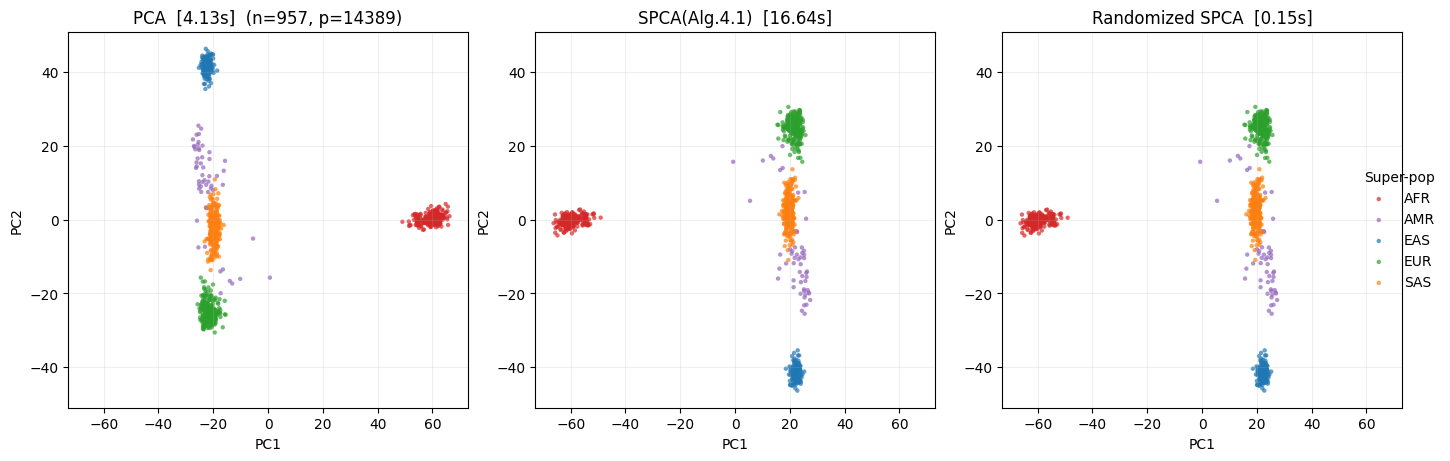

In [ ]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.decomposition import PCA

raw_path = '/kaggle/working/1kg/1kg_957x14389.raw'
lab_path = '/kaggle/working/1kg/labels_pop.tsv'

# Read RAW (any whitespace separator to avoid column misalignment)
raw = pd.read_csv(raw_path, sep=r'\s+', engine='python')
labels = pd.read_csv(lab_path, sep='\t', header=None, names=['FID','IID','POP'])

# Identify sample ID columns
id_aliases = {'FID','IID','#FID','#IID','PAT','MAT','SEX','PHENOTYPE'}
id_cols = [c for c in raw.columns if c in id_aliases]
if not id_cols:
    raw = raw.rename(columns={raw.columns[0]: 'IID'})
    id_cols = ['IID']
sample_id_col = 'IID' if 'IID' in raw.columns else id_cols[0]

# Build genotype matrix G (0/1/2) and standardize (same as smartpca)
G = raw.drop(columns=id_cols).to_numpy(float)
p = np.nanmean(G, axis=0) / 2.0                 # Allele frequency p_j
fill = (2.0 * p)[None, :]                        # 2p_j for each column (1 x p), for column-wise broadcasting
G = np.where(np.isnan(G), fill, G)               # Fill missing values with 2p_j (no shape conflict)
den = np.sqrt(2.0 * p * (1.0 - p))
den[den == 0] = 1.0
X = (G - (2.0 * p)[None, :]) / den[None, :]
n, p_ = X.shape

# 26 -> 5 super-population mapping
pop2super = {
    # AFR
    'ACB':'AFR','ASW':'AFR','ESN':'AFR','GWD':'AFR','LWK':'AFR','MSL':'AFR','YRI':'AFR',
    # AMR
    'CLM':'AMR','MXL':'AMR','PEL':'AMR','PUR':'AMR',
    # EAS
    'CDX':'EAS','CHB':'EAS','CHS':'EAS','JPT':'EAS','KHV':'EAS',
    # EUR
    'CEU':'EUR','FIN':'EUR','GBR':'EUR','IBS':'EUR','TSI':'EUR',
    # SAS
    'BEB':'SAS','GIH':'SAS','ITU':'SAS','PJL':'SAS','STU':'SAS'
}
labels_idx = labels.set_index('IID')
pops_26 = labels_idx.loc[raw[sample_id_col], 'POP'].to_numpy()
pops = np.array([pop2super.get(x, x) for x in pops_26])  # Aggregate to 5 super-populations

# Try to import your implementation; use built-in fallback if failed
try:
    from spca_variable_projection import spca_vp as _spca41
except Exception:
    _spca41 = None
try:
    from randomized_spca_vp import randomized_spca_vp as _rndspca
except Exception:
    _rndspca = None

def _soft(v, lam): return np.sign(v) * np.maximum(np.abs(v) - lam, 0.0)

def spca41_fallback(X, r=2, alpha=0.02, max_iter=200, tol=1e-6):
    Xw = X.copy(); V=[]; T=[]
    for k in range(r):
        u,s,vh = np.linalg.svd(Xw, full_matrices=False); v = vh[0]; v/= (np.linalg.norm(v)+1e-12)
        last = -1.0
        for _ in range(max_iter):
            t = Xw @ v; nt = np.linalg.norm(t);  t = t/(nt+1e-12)
            z = Xw.T @ t
            v_new = _soft(z, alpha); nv = np.linalg.norm(v_new)
            if nv==0: v_new=z; nv=np.linalg.norm(v_new)+1e-12
            v_new/=nv
            obj = float((Xw@v_new).T @ (Xw@v_new))
            if abs(obj-last) < tol*(1.0+abs(last)): v=v_new; break
            v, last = v_new, obj
        t = Xw @ v
        V.append(v.copy()); T.append(t.copy())
        Xw -= np.outer(t, (Xw.T@t)) / (np.dot(t,t)+1e-12)
    return np.stack(T,1), np.stack(V,1)

def rndspca_fallback(X, r=2, alpha=0.02, q_extra=8, n_power=1, max_iter=80, tol=1e-6, seed=42):
    rng = np.random.default_rng(seed); n,p = X.shape; q=r+q_extra
    Y = X @ rng.standard_normal((p,q))
    for _ in range(n_power): Y = X @ (X.T @ Y)
    Q,_ = np.linalg.qr(Y, mode='reduced'); B = Q.T @ X
    _,_,vh = np.linalg.svd(B, full_matrices=False); V = vh[:r].T
    for j in range(r):
        v = V[:,j]
        for _ in range(max_iter):
            t = X @ v; z = X.T @ (t/(np.linalg.norm(t)+1e-12))
            v_new = _soft(z, alpha); nv=np.linalg.norm(v_new)
            if nv==0: v_new=z; nv=np.linalg.norm(v_new)+1e-12
            v_new/=nv
            if abs(v_new@v - 1.0) < tol: v=v_new; break
            v = v_new
        V[:,j]=v
        for k in range(j+1,r):
            vk = V[:,k]; V[:,k] = vk - (v@vk)*v
            nv=np.linalg.norm(V[:,k]);  V[:,k] /= (nv if nv>0 else 1.0)
    return X @ V, V

# Parameters
r = 2; alpha = 0.02
times = {}

t0 = time.perf_counter()
T_pca = PCA(n_components=r, svd_solver='full').fit_transform(X)
times['PCA'] = time.perf_counter()-t0

t0 = time.perf_counter()
if _spca41 is not None: T_spca, V_spca = _spca41(X, r=r, alpha=alpha)
else:                   T_spca, V_spca = spca41_fallback(X, r=r, alpha=alpha)
times['SPCA(Alg4.1)'] = time.perf_counter()-t0

t0 = time.perf_counter()
if _rndspca is not None: T_rnd, V_rnd = _rndspca(X, r=r, alpha=alpha)
else:                    T_rnd, V_rnd = rndspca_fallback(X, r=r, alpha=alpha)
times['RND-SPCA'] = time.perf_counter()-t0

# Unified visualization (5 super-populations)
order = ['AFR','AMR','EAS','EUR','SAS']
order = [g for g in order if g in set(pops)]
colors = {'AFR':'tab:red','AMR':'tab:purple','EAS':'tab:blue','EUR':'tab:green','SAS':'tab:orange'}

def plot(ax, T, title):
    for g in order:
        idx = (pops==g)
        ax.scatter(T[idx,0], T[idx,1], s=10, alpha=0.7, c=colors[g], label=g, edgecolors='none')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title(title); ax.grid(True, alpha=0.2)

def limits(*Ts):
    xs = np.concatenate([t[:,0] for t in Ts]); ys = np.concatenate([t[:,1] for t in Ts])
    pad = lambda a,b: (a-0.05*(b-a), b+0.05*(b-a))
    return pad(xs.min(), xs.max()), pad(ys.min(), ys.max())

xlim, ylim = limits(T_pca, T_spca, T_rnd)
fig, axs = plt.subplots(1,3, figsize=(14,4.5), constrained_layout=True)
plot(axs[0], T_pca,  f'PCA  [{times["PCA"]:.2f}s]  (n={n}, p={p_})')
plot(axs[1], T_spca, f'SPCA(Alg.4.1)  [{times["SPCA(Alg4.1)"]:.2f}s]')
plot(axs[2], T_rnd,  f'Randomized SPCA  [{times["RND-SPCA"]:.2f}s]')
for ax in axs: ax.set_xlim(*xlim); ax.set_ylim(*ylim)
fig.legend(order, loc='center right', bbox_to_anchor=(1.03, 0.5), frameon=False, title='Super-pop')
out_png = '/kaggle/working/1kg/spca_scores_compare.png'
plt.savefig(out_png, dpi=160, bbox_inches='tight')
print('Saved figure to:', out_png)
print('Times (sec):', {k: round(v,3) for k,v in times.items()})

AIMS overlap with PCA (top-200):
{'SPCA∩PCA': 200, 'RND-SPCA∩PCA': 200}
Jaccard indices vs PCA:
{'SPCA': 1.0, 'RND-SPCA': 1.0}
Saved AIMS lists to: /kaggle/working/hapmap_like_1kg/AIMS_PCA_top200.tsv /kaggle/working/hapmap_like_1kg/AIMS_SPCA_top200.tsv /kaggle/working/hapmap_like_1kg/AIMS_RNDSPCA_top200.tsv
Saved figure to: /kaggle/working/hapmap_like_1kg/fig4_aims_compare.png


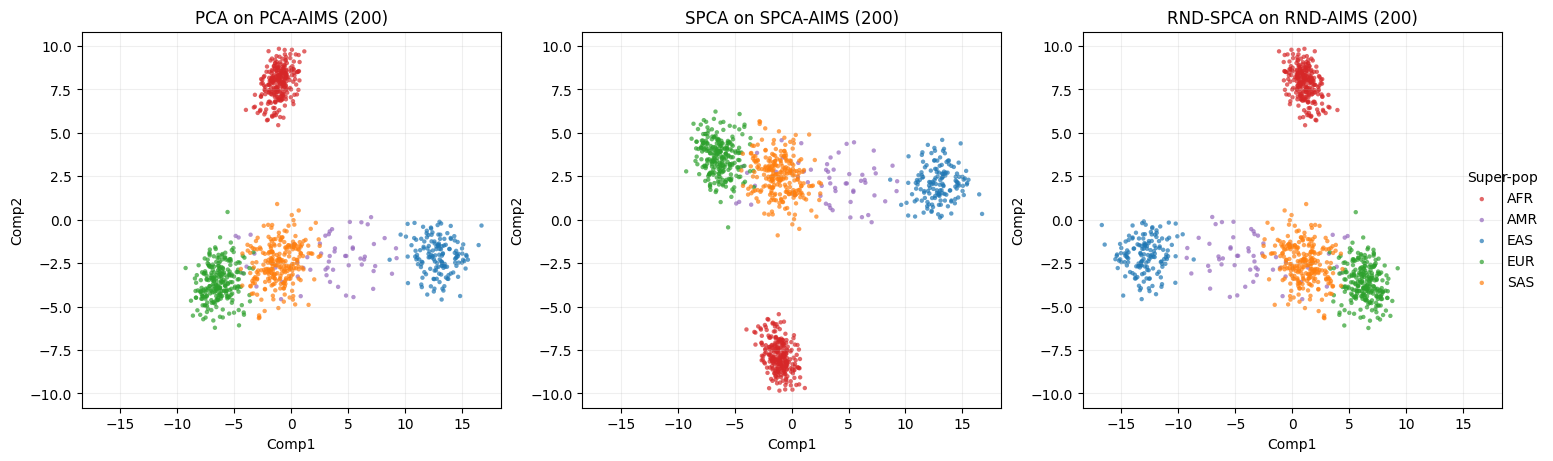

In [ ]:
# Select 200 AIMS based on first two principal component loadings, compare and visualize
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 0) Column names (SNP ID list)
var_cols = [c for c in raw.columns if c not in id_cols]
assert X.shape[1] == len(var_cols)

# 1) Compute loadings for three methods, score by |loading_PC1|+|loading_PC2|
# PCA loadings
_pca_model = PCA(n_components=2, svd_solver='full').fit(X)
P_load = _pca_model.components_.T  # (p, 2)
score_pca = np.sum(np.abs(P_load[:, :2]), axis=1)

# SPCA loadings (V_spca already computed above)
V_sp = V_spca
if V_sp.shape[0] != X.shape[1] and V_sp.shape[1] == X.shape[1]:
    V_sp = V_sp.T
score_spca = np.sum(np.abs(V_sp[:, :2]), axis=1)

# RND-SPCA loadings (V_rnd already computed above)
V_rs = V_rnd
if V_rs.shape[0] != X.shape[1] and V_rs.shape[1] == X.shape[1]:
    V_rs = V_rs.T
score_rnd = np.sum(np.abs(V_rs[:, :2]), axis=1)

# 2) Select top 200 AIMS
K = 200
idx_pca = np.argsort(-score_pca)[:K]
idx_spca = np.argsort(-score_spca)[:K]
idx_rnd = np.argsort(-score_rnd)[:K]

AIMS_pca = [var_cols[i] for i in idx_pca]
AIMS_spca = [var_cols[i] for i in idx_spca]
AIMS_rnd = [var_cols[i] for i in idx_rnd]

# Save lists
base = '/kaggle/working/1kg'
pd.Series(AIMS_pca).to_csv(f'{base}/AIMS_PCA_top200.tsv', index=False, header=False)
pd.Series(AIMS_spca).to_csv(f'{base}/AIMS_SPCA_top200.tsv', index=False, header=False)
pd.Series(AIMS_rnd).to_csv(f'{base}/AIMS_RNDSPCA_top200.tsv', index=False, header=False)

# 3) Overlap comparison with PCA
set_pca, set_spca, set_rnd = set(AIMS_pca), set(AIMS_spca), set(AIMS_rnd)

ovl_spca_pca = len(set_spca & set_pca)
ovl_rnd_pca  = len(set_rnd & set_pca)

def jacc(a, b):
    a, b = set(a), set(b)
    inter = len(a & b); uni = len(a | b)
    return inter / (uni + 1e-12)

print('AIMS overlap with PCA (top-200):')
print({'SPCA∩PCA': ovl_spca_pca, 'RND-SPCA∩PCA': ovl_rnd_pca})
print('Jaccard indices vs PCA:')
print({'SPCA': round(jacc(AIMS_spca, AIMS_pca), 4), 'RND-SPCA': round(jacc(AIMS_rnd, AIMS_pca), 4)})

# 4) 2D visualization of three methods on their respective AIMS
order = ['AFR','AMR','EAS','EUR','SAS']
order = [g for g in order if g in set(pops)]
colors = {'AFR':'tab:red','AMR':'tab:purple','EAS':'tab:blue','EUR':'tab:green','SAS':'tab:orange'}

# PCA on PCA-AIMS
t_pca = PCA(n_components=2, svd_solver='full').fit_transform(X[:, idx_pca])
# SPCA on SPCA-AIMS
if '_spca41' in globals() and _spca41 is not None:
    try:
        T_spca_aims, _ = _spca41(X[:, idx_spca], r=2, alpha=alpha)
    except TypeError:
        T_spca_aims, _ = _spca41(X[:, idx_spca], r=2, alpha=alpha)
else:
    # fallback: use the fallback mentioned above
    T_spca_aims, _ = spca41_fallback(X[:, idx_spca], r=2, alpha=alpha)
# RND-SPCA on RND-AIMS
if '_rndspca' in globals() and _rndspca is not None:
    try:
        T_rnd_aims, _ = _rndspca(X[:, idx_rnd], r=2, alpha=alpha)
    except TypeError:
        T_rnd_aims, _ = _rndspca(X[:, idx_rnd], r=2, alpha=alpha)
else:
    T_rnd_aims, _ = rndspca_fallback(X[:, idx_rnd], r=2, alpha=alpha)

# Unified coordinate range for horizontal comparison
def limits(*Ts):
    xs = np.concatenate([t[:,0] for t in Ts]); ys = np.concatenate([t[:,1] for t in Ts])
    pad = lambda a,b: (a-0.05*(b-a), b+0.05*(b-a))
    return pad(xs.min(), xs.max()), pad(ys.min(), ys.max())

xlim, ylim = limits(t_pca, T_spca_aims, T_rnd_aims)
fig, axs = plt.subplots(1,3, figsize=(15,4.5), constrained_layout=True)
for ax, T, title in [
    (axs[0], t_pca, 'PCA on PCA-AIMS (200)'),
    (axs[1], T_spca_aims, 'SPCA on SPCA-AIMS (200)'),
    (axs[2], T_rnd_aims, 'RND-SPCA on RND-AIMS (200)')
]:
    for g in order:
        idx = (pops==g)
        ax.scatter(T[idx,0], T[idx,1], s=10, alpha=0.7, c=colors[g], label=g, edgecolors='none')
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.set_xlabel('Comp1'); ax.set_ylabel('Comp2'); ax.set_title(title); ax.grid(True, alpha=0.2)
fig.legend(order, loc='center right', bbox_to_anchor=(1.03, 0.5), frameon=False, title='Super-pop')
plt.savefig(f'{base}/fig4_aims_compare.png', dpi=160, bbox_inches='tight')
print('Saved AIMS lists to:', f'{base}/AIMS_PCA_top200.tsv', f'{base}/AIMS_SPCA_top200.tsv', f'{base}/AIMS_RNDSPCA_top200.tsv')
print('Saved figure to:', f'{base}/fig4_aims_compare.png')
